# 3.5) (Exercises) Wildfire Susceptibility Mapping



---



**Credits**

This online tutorial would not be possible without invaluable contributions from [Andrea Trucchia](https://www.researchgate.net/profile/Andrea-Trucchia) (reduced data, methods), [Giorgio Meschi](https://www.linkedin.com/in/giorgio-meschi-86216b180/) (code, methods), and [Marj Tonini](https://www.researchgate.net/profile/Marj-Tonini-2) (presentation, methods). The methodology builds upon the following article:

[Trucchia, A.; Meschi, G.; Fiorucci, P.; Gollini, A.; Negro, D., Defining Wildfire Susceptibility Maps in Italy for Understanding Seasonal Wildfire Regimes at the National Level, *Fire*, (2022)](https://www.mdpi.com/2571-6255/5/1/30)

which generalizes the study below from the Liguria region (our case study) to all of Italy:

[Tonini, Marj, et al. "A machine learning-based approach for wildfire susceptibility mapping. The case study of the Liguria region in Italy." *Geosciences* 10.3 (2020): 105.](https://www.mdpi.com/2076-3263/10/3/105)



---



In week 3's final notebook, we will train classifiers on real [wildfire](https://en.wikipedia.org/wiki/Wildfire) data to map the fire risk in different regions of Italy. To keep the data size manageable, we will focus on the coastal [Liguria region](https://en.wikipedia.org/wiki/Liguria) that experiences a lot of wildfires, especially during the winter.

## Machine Learning for Environmental Risk Analysis

For environmental sciences practioners, one of the scenarios where machine learning can be particularly useful is risk analysis. Environmental risk analysis involves predicting where potential hazards may occur; it also involves understanding why some regions are more vulnerable to hazards than others. Machine learning models can be useful for these tasks because they can analyze large datasets containing different environmental predictors (e.g., weather conditions, soil conditions etc.) in an effective manner. By learning the hidden links between predictors and hazard risks, we may also gain new insights on what predictors or patterns are useful for creating early hazard warning systems.

In this exercise, we ask you to use the machine learning classifiers we learned in this chapter to recreate wildfire susceptibility maps for the Liguria region of Italy. The basic idea is to use ML classifiers to analyze a dataset with observations in weather conditions, vegetation cover, and topography information. The goal will be to understand how different factors enhance or reduce the probability of firefire in Liguria, which can help authorities and decision-makers to apply resources to critical areas for hazard prevention.

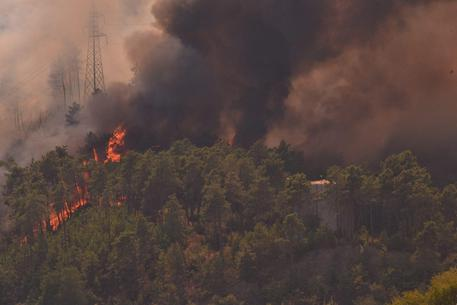

**Caption**: A wildfire in Italy. Can we predict which locations are most susceptible to wildfires using simple classifiers? 🔥

**Source**: [ANSA](https://www.ansa.it/english/news/2015/08/14/wildfires-in-italy-up-120-this-summer-on-past-two-years_f6e4eff7-ac07-4f9e-aa5a-e61f8c2ad7f2.html)

Let's start by downloading and loading the datasets into memory using the [`pooch`](https://pypi.org/project/pooch/) and [`GeoPandas`](https://geopandas.org/en/stable/) libraries:

In [46]:
# Install geopandas
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [47]:
import geopandas as gpd
import numpy as np
import pickle
import pooch

In [48]:
import pandas as pd

# Function to load the data
def load_data(path):

    # Load the content of the pickle file
    # (pd.read_pickle can read pickles written by older pandas versions)
    points_df = pd.read_pickle(path)

    # Convert it to a Geopandas `GeoDataFrame` for spatial analysis
    points_df = gpd.GeoDataFrame(points_df,
                                 geometry=gpd.points_from_xy(np.float64(points_df.x),
                                                             np.float64(points_df.y)))
    return points_df

In [49]:
# Fetch and cache verified snapshots of the Liguria wildfire dataset
WILDFIRE_FILES = {
    "points_liguria_vs0.1.pkl": "sha256:e8ebc70f972b5af4ef3d6110dcd61ce01ce5a830dcdb7d2c9e737aeab781606c",
    "fires_liguria_vs0.1.pkl": "sha256:361f067aafbac8add8f8a9a5c630df3c962cd37a2f125f420e7b9330fd0a1a4c",
}

def fetch_wildfire_file(filename):
    return pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-II/{filename}",
        known_hash=WILDFIRE_FILES[filename],
        fname=filename,
        path=pooch.os_cache("mlees"),
    )

variables_path = fetch_wildfire_file("points_liguria_vs0.1.pkl")
wildfires_path = fetch_wildfire_file("fires_liguria_vs0.1.pkl")


In [50]:
# Load the data and convert it to a GeoPandas `GeoDataFrame`
# This can take a minute
variables = load_data(variables_path)
wildfires = load_data(wildfires_path)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/pickle.py:1753: UserWarning: Unpickling a shapely <2.0 geometry object. Please save the pickle again as this compatibility may be removed in a future version of shapely.
  setstate(state)



### Part I: Pre-Processing the Dataset for Classification

**Q1) After analyzing the topography and land cover data provided in `variables`, create your input dataset `inputs` from `variables` to predict the occurence of wildfires (`wildfires`). Keep at least one categorical variable (`veg`, `bioclim`, or `phytoclim`).**

Hint 1: Refer to the documentation [at this link](https://github.com/mirkodandrea/liguria-fire-susceptibility/blob/master/variables%20explaination.md) to know what the different `keys` of `variables` refer to.

Hint 2: You may refer to Table 1 of [Tonini et al.](https://www.mdpi.com/2076-3263/10/3/105), copied below, to choose your input variables, although we recommend starting with less inputs at first to build a simpler model and avoid overfitting.

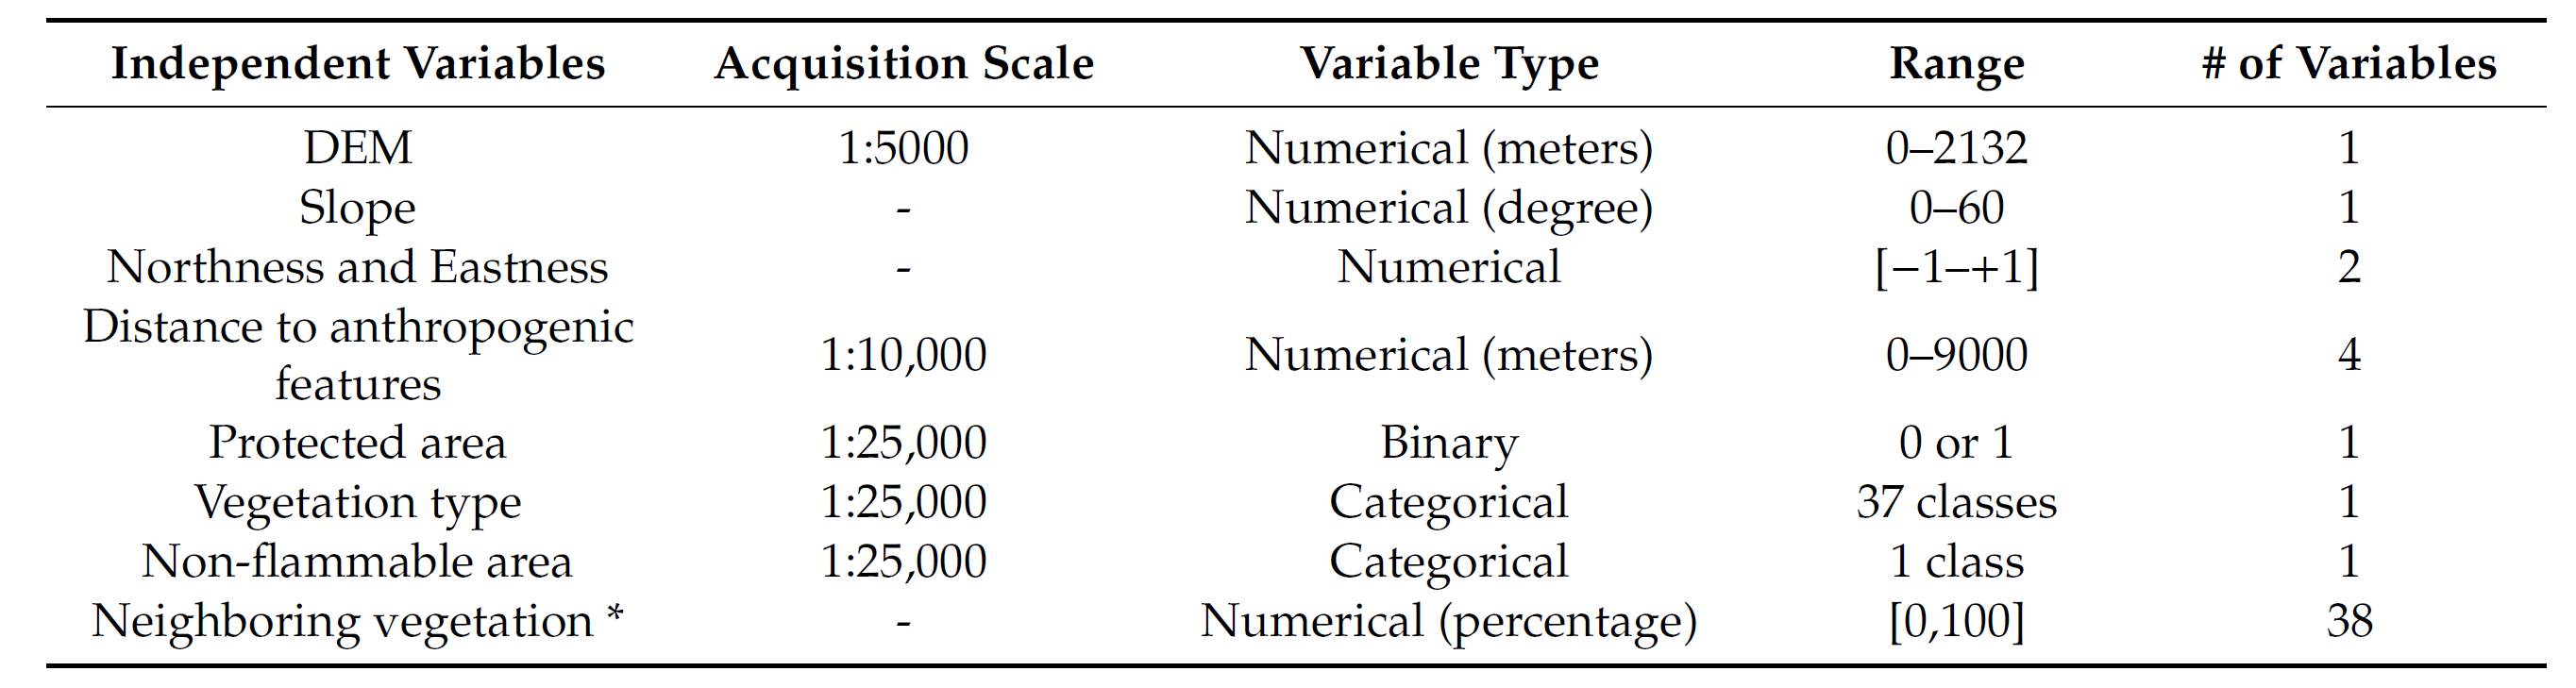

Here are some pandas commands you could use to explore your data.
[.head()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html)
[.columns()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html)
[.describe()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)

In [51]:
# Explore the `variables` dataset
#########################################################################################################
# 1. What kind of data is provided in the "variables" panda DataFrame?
#########################################################################################################
# Can you print the variable names?
print(variables.columns)

Index(['row', 'col', 'x', 'y', 'dem', 'slope', 'north', 'east', 'veg',
       'urban_d', 'roads_d', 'crops_d', 'tracks_d', 'bioclim', 'phytoclim',
       'temp_1', 'temp_2', 'prec_1', 'prec_2', 'perc_0', 'perc_21', 'perc_22',
       'perc_23', 'perc_32', 'perc_33', 'perc_34', 'perc_37', 'point_index',
       'geometry'],
      dtype='object')


In [52]:
# Can you print a table with all the statistics of each variable in the dataframe?
print(variables.describe())

                 row            col             x             y  \
count  528669.000000  528669.000000  5.286690e+05  5.286690e+05   
mean      456.389826     962.931258  1.475397e+06  4.901395e+06   
std       240.887463     555.848154  5.558482e+04  2.408875e+04   
min         1.000000       1.000000  1.379204e+06  4.848434e+06   
25%       256.000000     491.000000  1.428204e+06  4.882034e+06   
50%       411.000000     894.000000  1.468504e+06  4.905934e+06   
75%       650.000000    1463.000000  1.525404e+06  4.921434e+06   
max       986.000000    2065.000000  1.585604e+06  4.946934e+06   

                 dem          slope          north           east  \
count  528669.000000  528669.000000  528669.000000  528669.000000   
mean      538.422731      18.021345      -0.097896       0.017473   
std       336.707659       8.176142       0.701160       0.706036   
min         0.000000       0.000000      -1.000000      -1.000000   
25%       281.000000      12.281326      -0.787887 

There are 25 columns (variables) in the DataFrame. It is probably best to start simple and just use a few variables to make the wildfire prediction.

Can we use a very simple model to predict wildfires ❓

A simple model might contain `dem`, `slope`, `veg` and `bioclim`. We can use it as a baseline to evaluate model performance when you use other combinations to train the model.

However, we cannot tell you which combination would perform the best as we have not done an extensive search while preparing the notebook.

In [53]:
# Here you will filter the DataFrame so that only the variables you want are in the input
############################################################################################################
# 1. Drop down the names of variables you want here so that pandas can do the filtering for you.
############################################################################################################
vars_tokeep = ['dem', 'slope', 'veg', 'bioclim']

In [54]:
############################################################################################################
# 2. Create a new dataframe 'inputs' with just the variables you want
############################################################################################################
inputs = variables[vars_tokeep] # Filter 'variables' dataframe
inputs.head() # print the first few rows to make sure everything works fine

,dem,slope,veg,bioclim
point_index,,,,
0,563,20.843185,34,15
1,527,23.599121,34,15
2,525,26.699856,34,15
3,519,24.512413,34,15
4,532,20.421495,34,15


**Q2) To avoid making inaccurate assumptions about which types of vegetation and non-flammable area are most similar, convert your categorical inputs into one-hot vectors.**

Hint 1: You may use the [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html#sklearn.preprocessing.OneHotEncoder.fit_transform) method of `scikit-learn`'s [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) class to convert categorical inputs into one-hot vectors.

Hint 2: Don't forget to remove the categorical variables from your input dataset, e.g. using [`drop`](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.html) if you are still using a `GeoDataFrame`, or [`del`](https://docs.python.org/3/reference/simple_stmts.html#the-del-statement)/[`pop`](https://docs.python.org/3/library/stdtypes.html#dict.pop) if you are working with a Python dictionary.

Hint 3: There are numerous ways to change the categorical data into one-hot vectors. It is quite easy to do in `pandas`, but scikit-learn also provides some transformers that could be useful, including [.ColumnTransformer()](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html) and [Pipeline()](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

In the guided reading, you have seen how these functions are used. Try experiment with them and see if you prefer using these scikit transformers or pandas.

In [55]:
############################################################################################################
# 1. Import OneHotEncoder for 'veg' and 'bioclim' data, and pandas
############################################################################################################
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
############################################################################################################
# 2. Initiate OneHotEncoder object, set the 'sparse_output' option to False
############################################################################################################
enc = OneHotEncoder(sparse_output=False)

In [56]:
############################################################################################################
# 3. Convert categorical variables into one-hot vectors
############################################################################################################
# Convert categorical variables with 'enc'
veg_onehot = enc.fit_transform(variables[['veg']])
bioclim_onehot = enc.fit_transform(variables[['bioclim']])
# Convert 'veg_onehot' and 'bioclim_onehot' to pandas DataFrames
# (we keep the original row index so that the DataFrames can be joined safely below)
veg_transform = pd.DataFrame(veg_onehot) # veg
bio_transform = pd.DataFrame(bioclim_onehot) # bioclim

############################################################################################################
# 4. Print the shape of 'veg_transform'
############################################################################################################
print(veg_transform.shape)
# Don't change these!
veg_transform= veg_transform.add_prefix('v_')
bio_transform= bio_transform.add_prefix('b_')

(528669, 7)


In [57]:
############################################################################################################
# 5. Convert 'inputs' into Panda DataFrame
############################################################################################################
inputs_gdf = pd.DataFrame(inputs).reset_index(drop=True)
############################################################################################################
# 6. Add 'veg_transform' and 'bio_transform' into the inputs DataFrame
############################################################################################################
inputs_gdf = inputs_gdf.join(veg_transform)
inputs_gdf = inputs_gdf.join(bio_transform)

In [58]:
############################################################################################################
# 7. Use .drop() to delete 'veg' and 'bioclim' from DataFrame
############################################################################################################
# .drop() returns a new DataFrame, so we assign it back (otherwise the categorical columns would stay in `inputs_gdf`)
inputs_gdf = inputs_gdf.drop(columns=['veg', 'bioclim'])
print(inputs_gdf.shape)
inputs_gdf.head()

(528669, 14)


,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,563,20.843185,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,527,23.599121,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,525,26.699856,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,519,24.512413,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,532,20.421495,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Now that we built our `inputs` dataset, we are ready to build our `outputs` dataset!

**Q3) Using the `point_index` column of `wildfires` and `variables`, create your `outputs` dataset, containing 1 when there was a wildfire and 0 otherwise.**

Hint: Check that `inputs` and `outputs` have the same number of cases by looking at their `.shape[0]` attribute.

In [59]:
#####################################################################################################################
# 1. Use numpy to initialize an outputs array with the same shape as the 'point_index' column in the variables table
#####################################################################################################################
outputs = np.zeros_like(variables['point_index'], dtype=int)
#####################################################################################################################
# 2. Pull out the indices of wildfire locations from the pandas DataFrame 'wildfires'
#####################################################################################################################
wildfiresindex = wildfires.index

In [60]:
#####################################################################################################################
# 3. Fill the zero array with ones if a fire broke out at a specific location index.
# Here you can use a for loop for this task
#####################################################################################################################
# position of every `point_index` in the `variables` table (so this also works if point_index is not simply 0, 1, 2, ...)
outputs = np.isin(variables['point_index'].to_numpy(), wildfires.index.to_numpy()).astype(int)

In [61]:
#####################################################################################################################
# 4. Check that `inputs` and `outputs` have the same shape[0]
#####################################################################################################################

print(inputs_gdf.shape[0], outputs.shape[0])
assert inputs_gdf.shape[0] == outputs.shape[0]
print(f"Fraction of points with a wildfire: {outputs.mean():.3f}")

528669 528669
Fraction of points with a wildfire: 0.155


**Q4) Separate your `inputs` and `outputs` datasets into a training and a test set. Keep at least 20% of the dataset for testing.**

Hint 1: You may use `scikit-learn`'s [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function.

Hint 2: If you are considering optimizing the hyperparameters of your classifier, form a validation dataset as well.

Hint 3: We recommend performing the split on the indices so that it is easier to track what points are in which dataset after splitting. You will have an easier time when plotting the susceptibility map.

In [62]:
#####################################################################################################################
# 1. Import train_test_split()
#####################################################################################################################
from sklearn.model_selection import train_test_split

In [63]:
#####################################################################################################################
# 2. Create a list with all indices in the input [0,1,2,...]
#####################################################################################################################
all_indices = list(range(len(inputs_gdf)))

#####################################################################################################################
# 3. Convert the inputs_gdf dataframe to numpy array
#####################################################################################################################
feature_names = inputs_gdf.columns.tolist() # remember the column names, we will need them later
inputs_gdf = inputs_gdf.to_numpy()

#####################################################################################################################
# 4. Apply train_test_split on 'all_indices', and store training indices in 'indx_train', test indices in 'indx_test'
#####################################################################################################################
indx_train, indx_test = train_test_split(all_indices, test_size=0.2, random_state=42)

#####################################################################################################################
# 5. Create training and test sets with indx_train and indx_test
#####################################################################################################################
X_train, X_test, y_train, y_test = inputs_gdf[indx_train], inputs_gdf[indx_test], outputs[indx_train], outputs[indx_test]

In [64]:
# Check the shape of your training(/validation)/test sets
# and make sure you kept at least 20% of your dataset for testing
print("train:", X_train.shape, y_train.shape)
print("test: ", X_test.shape, y_test.shape)
print(f"Fraction of the dataset kept for testing: {len(y_test) / len(outputs):.2f}")

train: (422935, 14) (422935,)
test:  (105734, 14) (105734,)
Fraction of the dataset kept for testing: 0.20


Congratulations, you have created a viable wildfire dataset to train a machine learning classifier! 😃 Now let's get started 🔥

### Part II: Training and Benchmarking the Machine Learning Classifiers

**Q5) Now comes the machine learning fun! 🤖 Train multiple classifiers on your newly-formed training set, and make sure that at least one has the `predict_proba` method once trained.**

Hint: You may train a [`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) or an [`ExtraTreesClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html), but we encourage you to be creative and include additional classifiers you find promising! 💻

In [65]:
#####################################################################################################################
# 1. Import RandomForestClassifier
#####################################################################################################################
from sklearn.ensemble import RandomForestClassifier
#####################################################################################################################
# 2. Convert X_train and X_test into pandas DataFrame
#####################################################################################################################
X_train = pd.DataFrame(X_train, columns=feature_names)
X_test = pd.DataFrame(X_test, columns=feature_names)

In [66]:
X_train

,dem,slope,v_0,v_1,v_2,v_3,v_4,v_5,v_6,b_0,b_1,b_2,b_3,b_4
0,143.0,3.441056,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,204.0,21.165070,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,304.0,28.740286,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,318.0,18.950947,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,522.0,19.906359,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
422930,431.0,14.090720,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
422931,560.0,3.790979,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
422932,213.0,19.034899,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
422933,413.0,0.955438,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [67]:
#####################################################################################################################
# 3. Initiate RF classifier and fit it on training set
#####################################################################################################################
rfc = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rfc.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [68]:
# Q5 asks for *multiple* classifiers: let's add two more that also have `predict_proba`
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

etc = ExtraTreesClassifier(n_estimators=100, n_jobs=-1, random_state=42)
etc.fit(X_train, y_train)

hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)

HistGradientBoostingClassifier(random_state=42)

In [69]:
# (Optional) Conduct a hyperparameter search on the validation set
# e.g., using scikit-learn's RandomizedSearchCV
# Switch RUN_SEARCH to True to run it (it takes a while). The search uses 3-fold cross-validation *inside the
# training set*, so the test set stays untouched.
RUN_SEARCH = False

if RUN_SEARCH:
    from sklearn.model_selection import RandomizedSearchCV
    param_distributions = {
        'n_estimators': [100, 200, 400],
        'max_depth': [None, 10, 20, 40],
        'min_samples_leaf': [1, 2, 5, 10],
        'max_features': ['sqrt', 0.5, 1.0],
    }
    search = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                                param_distributions, n_iter=10, cv=3,
                                scoring='roc_auc', random_state=42)
    search.fit(X_train, y_train)
    print(search.best_params_, round(search.best_score_, 3))
    rfc = search.best_estimator_ # keep the tuned forest as our main classifier

**Q6) Compare the performance and confusion matrices of your classifiers on the test set. Which classifier performs best in your case?**

Hint 1: You may use the [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) to quantify your classifier's performance, but don't forget there are [many other performance metrics to benchmark binary classifiers](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

Hint 2: You can directly calculate the confusion matrix using `scikit-learn`'s [`confusion_matrix` function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

In [70]:
#####################################################################################################################
# 1. Import accuracy_score, confusion_matrix, and ConfusionMatrixDisplay
#####################################################################################################################
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [71]:
#####################################################################################################################
# 2. Use rfc to make prediction on test set
#####################################################################################################################
rfc_preds = rfc.predict(X_test)

In [72]:
#####################################################################################################################
# 3. Use accuracy_score to infer trained classifier performance
#####################################################################################################################
rfc_acc = accuracy_score(y_test, rfc_preds)
print(f"Random forest accuracy on the test set: {rfc_acc:.3f}")

Random forest accuracy on the test set: 0.853


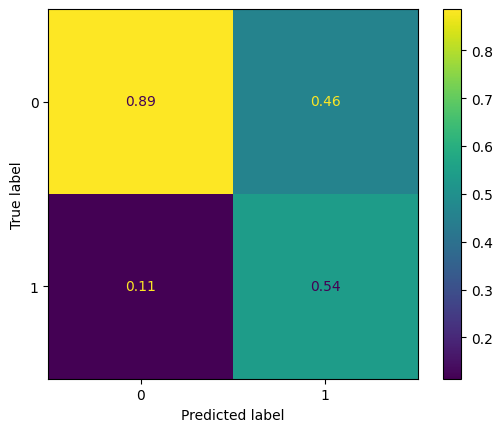

In [73]:
#####################################################################################################################
# 4. Plot the confusion matrix
#####################################################################################################################
cm = confusion_matrix(y_test, rfc_preds, normalize='pred') # Get a confusion matrix 'cm', use 'pred' for the normalize option
disp = ConfusionMatrixDisplay(confusion_matrix = cm) # Use ConfusionMatrixDisplay to visualize 'cm'
disp.plot()

                         accuracy  balanced accuracy  ROC AUC
classifier                                                   
Random forest               0.853              0.643    0.739
Extra trees                 0.847              0.640    0.731
Hist. gradient boosting     0.855              0.565    0.763


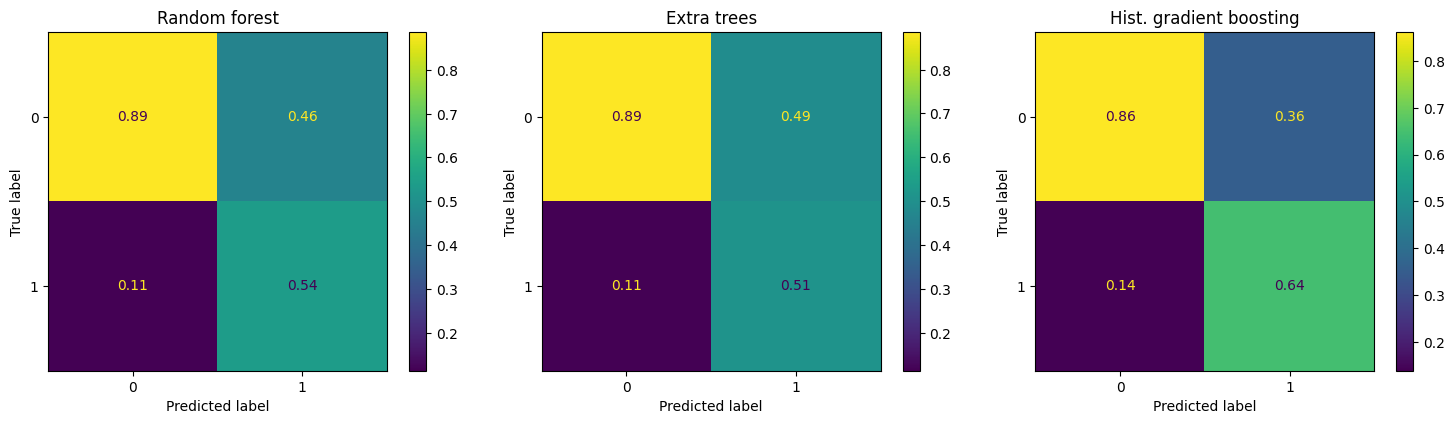

In [74]:
# Compare all classifiers on the test set (accuracy alone can hide a class imbalance, so we also look at
# balanced accuracy and ROC AUC)
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

classifiers = {'Random forest': rfc, 'Extra trees': etc, 'Hist. gradient boosting': hgb}

rows = []
for name, clf in classifiers.items():
    pred = clf.predict(X_test)
    proba = clf.predict_proba(X_test)[:, 1]
    rows.append({'classifier': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'balanced accuracy': balanced_accuracy_score(y_test, pred),
                 'ROC AUC': roc_auc_score(y_test, proba)})
scores = pd.DataFrame(rows).set_index('classifier').round(3)
print(scores)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, clf) in zip(axes, classifiers.items()):
    ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, normalize='pred', ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Which classifier performs best?** Read it off the table above (check your own numbers, they depend on the inputs you picked): the best classifier is the one with the highest **ROC AUC / balanced accuracy**, not necessarily the highest plain accuracy. For hazard mapping, it is also worth reading the confusion matrices: a *missed* fire (a fire pixel predicted as "no fire") is usually more costly than a *false alarm*. Tree ensembles (random forest, extra trees) and gradient boosting usually end up close to each other on a small input set like `dem`, `slope`, `veg` and `bioclim`; if the gap is small, prefer the simpler/faster model, or the one with the more sensible susceptibility map in Part III.

For comparison, below is the confusion matrix obtained by the paper's authors:


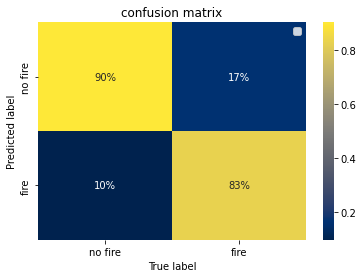

### Part III: Making the Susceptibility Map

**Q7) Using all the classifiers you trained that have a `predict_proba` method, predict the probability of a wildfire over the entire dataset.**

Hint: `predict_proba` will give you the probability of both the presence and absence of a wildfire, so you will have to select the right probability.

In [75]:
#####################################################################################################################
# 1. Predict the probability of a wildfire or not on the *entire* dataset
#####################################################################################################################
X_all = pd.DataFrame(inputs_gdf, columns=feature_names) # entire dataset, same columns as the training set
predprob_rf = rfc.predict_proba(X_all) # Use .predict_proba in the 'rfc' classifier to process the entire dataset

In [76]:
#####################################################################################################################
# 2. Extract the probability of a wildfire happening over the entire period of the dataset for each instance
#####################################################################################################################
rf_testprob_fire = predprob_rf[:, 1] # Hint: predprob_rf shape = [:,2], select the second column

In [77]:
# Same thing for the other classifiers that have a `predict_proba` method
et_testprob_fire = etc.predict_proba(X_all)[:, 1]
hgb_testprob_fire = hgb.predict_proba(X_all)[:, 1]

**Q8) Make the susceptibility map 🔥**

Hint 1: The `x` and `y` coordinates for the map can be extracted from the `variables` dataset.

Hint 2: You can simply [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) `x` versus `y`, and color the dots according to their probabilities (`c`=probability of a wildfire) to get the susceptibility map.

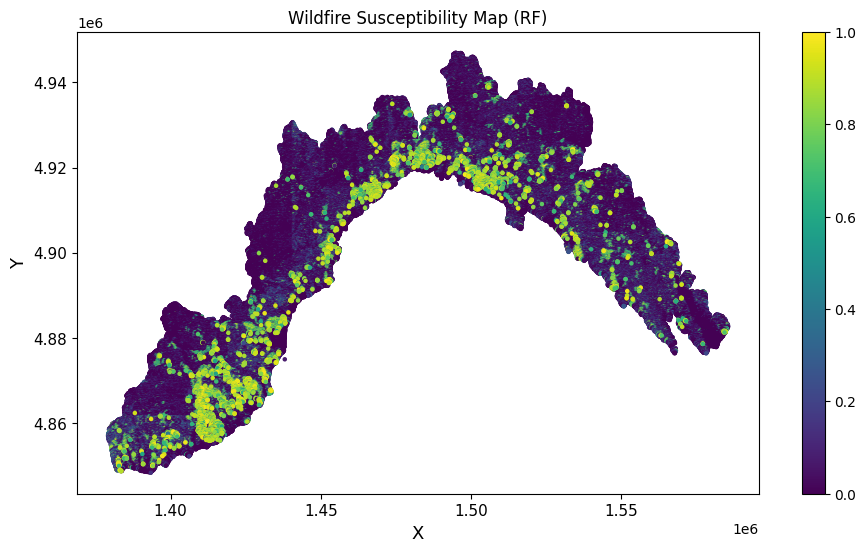

In [78]:
# Scatter ['x'] vs ['y'] columns in the entire dataframe and color the dots with the predicted probability 'rf_testprob_fire'
# to make the susceptibility map

import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,figsize=(6+5,4+2))
cmploy = ax.scatter(variables['x'],variables['y'],s=5,c=rf_testprob_fire,cmap='viridis')
plt.colorbar(cmploy,ax=ax)
ax.set_title('Wildfire Susceptibility Map (RF)')
ax.set_ylabel('Y',size=13)
ax.set_xlabel('X',size=13)
ax.tick_params(axis='both', which='major', labelsize=11)
plt.show()

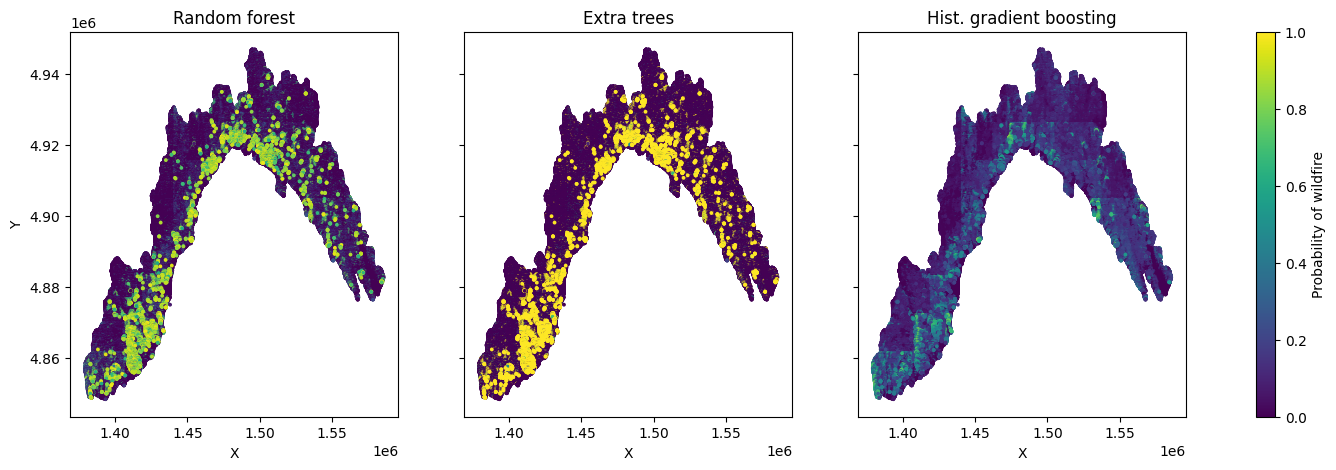

In [79]:
# Do the three classifiers agree on where the susceptible areas are? Same color scale for a fair comparison
maps = {'Random forest': rf_testprob_fire, 'Extra trees': et_testprob_fire, 'Hist. gradient boosting': hgb_testprob_fire}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, prob) in zip(axes, maps.items()):
    sc = ax.scatter(variables['x'], variables['y'], s=3, c=prob, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel('X')
axes[0].set_ylabel('Y')
fig.colorbar(sc, ax=axes, label='Probability of wildfire')
plt.show()

You should get a susceptibility map that looks like the one below. Does your susceptibility map depend on the classifier & the inputs you chose? Which map would you trust most?

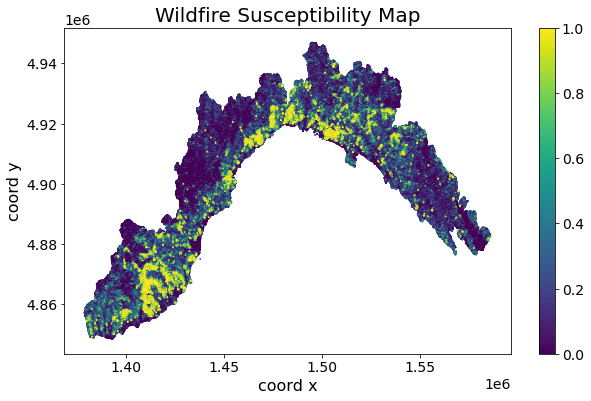

It seems like our model was too simple to generate a useful map 😞 .
Your TA actually experimented training a RandomForest model with 10 variables and got a 91% accuracy!

So you should definitely try combinations of different variables to get a map that is better than what you just got.



**Does the map depend on the classifier and the inputs? Which map would you trust most?** Yes, on both. Inspect your own maps, but typically:

- **Inputs matter most.** With only `dem`, `slope`, `veg` and `bioclim`, the map mostly reproduces broad elevation/vegetation gradients; the probabilities are poorly separated (compressed around the base rate), which is what the TA's note above means by "too simple". Adding weather, climate and anthropogenic inputs (see the bonus exercise) sharpens it.
- **Classifier matters less.** Random forest, extra trees and gradient boosting usually agree on the large-scale pattern and differ in fine detail (extra trees tends to be smoother, boosting more contrasted).
- **Which to trust?** The map from the model with the best *held-out* score (ROC AUC / balanced accuracy on the test set), whose most important inputs make physical sense, and which is stable when the inputs or random seed change. Note that the maps above are predicted on the *entire* dataset, including the training points, so they look better than they really are on unseen locations.

## Bonus Exercise 4: Exploring the Susceptibility Map's Sensitivity to Seasonality and Input Selection

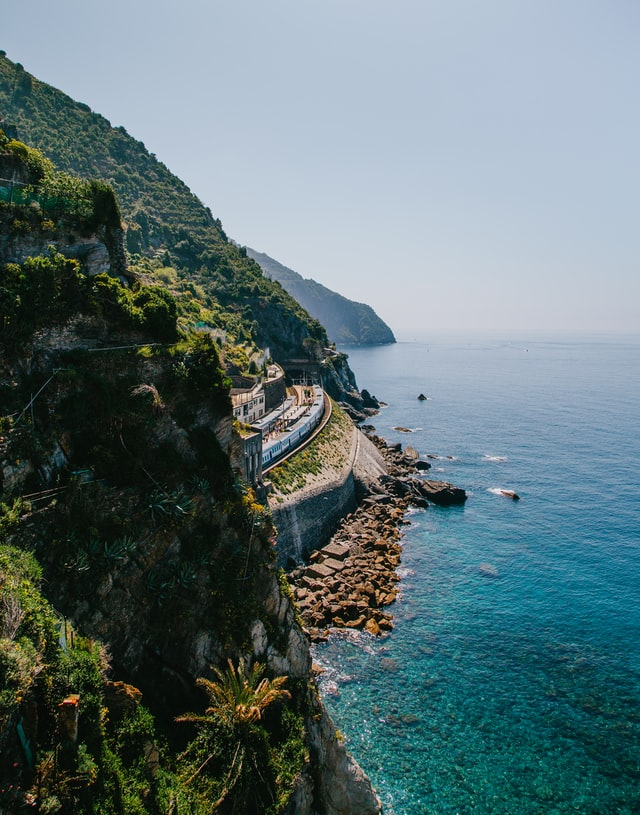

**Caption:** The Liguria region (Cinque Terre), after you save it from raging wildfires using machine learning ✌

### Part I: Seasonality

**Q1) Using the `season` column of `wildfires`, separate your data into two seasonal datasets (1=Winter, 2=Summer).**

Hint: When splitting your `inputs` into two seasonal datasets, keep in mind that `temp_1` and `prec_1` are the climatological mean temperatures and precipitation during winter, while `temp_2` and `prec_2` are the climatological mean temperature and precipitation during summer.  

In [80]:
# Identify indices for which the wildfires occured during winter/summer
winter_idx = wildfires.loc[wildfires['season'] == 1, 'point_index'].to_numpy()
summer_idx = wildfires.loc[wildfires['season'] == 2, 'point_index'].to_numpy()
print("winter fires:", len(winter_idx), "| summer fires:", len(summer_idx))

KeyError: 'point_index'

In [ ]:
# Use these indices to split your `inputs` and `outputs` datasets
# into two seasonal datasets

# --- outputs: 1 if a fire broke out *in that season* at the point, 0 otherwise
point_index = variables['point_index'].to_numpy()
outputs_winter = np.isin(point_index, winter_idx).astype(int)
outputs_summer = np.isin(point_index, summer_idx).astype(int)

# --- inputs: a plain DataFrame version of `variables` (no geometry) and the different groups of variables
vdf = pd.DataFrame(variables.drop(columns=['geometry'], errors='ignore'))
cat_vars = [c for c in ['veg', 'bioclim', 'phytoclim'] if c in vdf.columns]          # categorical variables
meta_cols = ['x', 'y', 'point_index']                                                 # coordinates / ids: never inputs
num_vars = [c for c in vdf.columns
            if c not in meta_cols + cat_vars and pd.api.types.is_numeric_dtype(vdf[c])]
all_vars = num_vars + cat_vars
print("numeric inputs:", num_vars)
print("categorical inputs:", cat_vars)

def make_features(var_list, season=None):
    """Build an input DataFrame from a list of variable names.
    - numeric variables are kept as they are (missing values filled with the median),
    - categorical variables are one-hot encoded,
    - if `season` is 1 (winter) or 2 (summer), the seasonal climate variables (temp_1/prec_1 vs temp_2/prec_2, ...)
      are restricted to that season and renamed temp, prec, ... so both seasons share the same input names."""
    num = [v for v in var_list if v not in cat_vars]
    X = vdf[num].copy()
    if season is not None:
        keep = [c for c in X.columns if not (c[-2:] in ('_1', '_2') and c[-1] != str(season))]
        X = X[keep].rename(columns=lambda c: c[:-2] if c.endswith(f'_{season}') else c)
    X = X.fillna(X.median())
    cats = [v for v in var_list if v in cat_vars]
    if cats:
        X = pd.concat([X, pd.get_dummies(vdf[cats], columns=cats, dtype=float)], axis=1)
    return X

inputs_winter = make_features(all_vars, season=1)
inputs_summer = make_features(all_vars, season=2)

In [ ]:
# Verify that for each season, the shape[0] of your
# `inputs` and `outputs` sets are the same
print("winter:", inputs_winter.shape, outputs_winter.shape)
print("summer:", inputs_summer.shape, outputs_summer.shape)
assert inputs_winter.shape[0] == outputs_winter.shape[0]
assert inputs_summer.shape[0] == outputs_summer.shape[0]

**Q2) Use these two seasonal datasets to make the Liguria winter and summer susceptibility maps using your best classifier(s). What do you notice?**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [ ]:
# So many things to recycle: let's wrap the "split -> train -> score -> map" steps into small functions
from sklearn.metrics import roc_auc_score

def fit_rf(X, y, seed=42, n_estimators=100):
    """Train a random forest on 80% of the data and report the score on the held-out 20%."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    rf = RandomForestClassifier(n_estimators=n_estimators, n_jobs=-1, random_state=seed)
    rf.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, rf.predict(X_te))
    auc = roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1])
    print(f"accuracy = {acc:.3f} | ROC AUC = {auc:.3f} (on {len(y_te)} held-out points)")
    return rf, X_te, y_te

def plot_map(prob, title, ax=None, vmin=0, vmax=1, cmap='viridis', label='Probability of wildfire'):
    """Susceptibility map: scatter x vs y, colored by `prob`."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    sc = ax.scatter(vdf['x'], vdf['y'], s=4, c=prob, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    return ax

In [ ]:
# Much training: winter model
rf_winter, Xte_winter, yte_winter = fit_rf(inputs_winter, outputs_winter)
prob_winter = rf_winter.predict_proba(inputs_winter)[:, 1]

In [ ]:
# Recycling: summer model
rf_summer, Xte_summer, yte_summer = fit_rf(inputs_summer, outputs_summer)
prob_summer = rf_summer.predict_proba(inputs_summer)[:, 1]

In [ ]:
# Compare the winter and summer susceptibility maps
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
plot_map(prob_winter, 'Winter susceptibility', ax=axes[0])
plot_map(prob_summer, 'Summer susceptibility', ax=axes[1])
m = np.abs(prob_winter - prob_summer).max()
plot_map(prob_winter - prob_summer, 'Winter minus summer', ax=axes[2], vmin=-m, vmax=m, cmap='RdBu_r',
         label='Difference in probability')
plt.tight_layout()
plt.show()

**What do you notice?** Compare the three panels above with your own results. The two seasons are trained on the same static inputs (terrain, land cover) but *different* climate inputs (`temp_1`/`prec_1` vs `temp_2`/`prec_2`) and *different* fire locations, so the susceptible areas generally do not coincide: the "winter minus summer" panel shows where the model thinks a given location is more fire-prone in one season than the other. Wildfire regimes are seasonal (different ignition causes, fuel moisture and weather), so a single all-year map averages over two quite different situations and a season-specific map is more useful for planning prevention. Also check the printed scores: a season with fewer fires has fewer positive examples and therefore a noisier model.

### Part II: Input Selection

The details of the susceptibility map may strongly depend on the inputs you chose from the `variables` dataset. Here, we explore two different ways of selecting inputs to make our susceptibility maps as robust as possible.

**Q3) Using your best classifier, identify the inputs contributing the most to your model's performance using [permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html).**

Hint: You may use `scikit-learn`'s [`permutation_importance` function](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) using your best classifier as your `estimator`.

In [ ]:
# Import the necessary functions and classes
from sklearn.inspection import permutation_importance

In [ ]:
# Calculate the permutation importance of each of your model's inputs
# "Best classifier" = random forest, now trained on *all* the inputs (both seasons' climate included, whole-year fires)
X_full = make_features(all_vars)
rf_full, Xte_full, yte_full = fit_rf(X_full, outputs)

perm = permutation_importance(rf_full, Xte_full, yte_full, n_repeats=5, scoring='roc_auc',
                              random_state=0, n_jobs=-1)

In [ ]:
# One-hot encoded variables are spread over several columns: add the importance of the columns that belong
# to the same original variable (an approximation, but good enough to rank the variables)
def parent_var(col):
    for c in cat_vars:
        if col.startswith(c + '_'):
            return c
    return col

imp_cols = pd.Series(perm.importances_mean, index=Xte_full.columns)
imp_vars = imp_cols.groupby(parent_var).sum().sort_values(ascending=False)

In [ ]:
# Display the result and identify the most important inputs
print(imp_vars.round(4).head(15))

fig, ax = plt.subplots(figsize=(7, 5))
imp_vars.head(15)[::-1].plot.barh(ax=ax)
ax.set_xlabel('Drop in ROC AUC when the input is shuffled')
ax.set_title('Permutation importance')
plt.tight_layout()
plt.show()

**Q4) Retrain the same type of classifier only using the inputs you identified as most important, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [ ]:
# Lots of recycling: keep the k most important variables (k can be changed)
k = 5
top_vars = imp_vars.head(k).index.tolist()
print("Selected with permutation importance:", top_vars)
X_top = make_features(top_vars)

In [ ]:
# of retraining: same classifier, fewer inputs
rf_top, Xte_top, yte_top = fit_rf(X_top, outputs)

In [ ]:
# and re-predicting on the entire dataset (the full-input model is kept for the comparison)
prob_full = rf_full.predict_proba(X_full)[:, 1]
prob_top = rf_top.predict_proba(X_top)[:, 1]

In [ ]:
# Make the new susceptibility map
fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
plot_map(prob_full, f'All inputs ({X_full.shape[1]} columns)', ax=axes[0])
plot_map(prob_top, f'{k} most important inputs (permutation)', ax=axes[1])
m = np.abs(prob_full - prob_top).max()
plot_map(prob_top - prob_full, 'Reduced minus full', ax=axes[2], vmin=-m, vmax=m, cmap='RdBu_r', label='Difference in probability')
plt.tight_layout()
plt.show()

Can you explain the differences in susceptibility maps based on the inputs' spatial distribution?

**Why do the maps differ?** A map built from a handful of inputs inherits the spatial pattern of those inputs: if they are smooth, strongly spatially-structured fields (elevation, distance to the coast or to roads, climatology), the map becomes smoother and more "banded"; fine-scale detail from the dropped inputs disappears. Keep in mind that permutation importance has limits: when two inputs are strongly correlated, shuffling one barely hurts the model (the other compensates), so *both* can look unimportant; and when a model has learned a spurious correlation, that correlation is reported as importance. If your reduced map is very different from the full one, that is a hint that one of these happened, which is what the next step addresses.

If the susceptibility map changed a lot, our best classifier may initially have learned spurious correlations. This would have affected our permutation feature importance analysis, and motivates re-selecting our inputs from scratch! 🔨

**Q5) Use the [`SequentialFeatureSelector`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SequentialFeatureSelector.html) to select the most important inputs. Select as few as possible!**

Hint: Track how the score improves as you add more and more inputs via `n_features_to_select`, and stop when it's "good enough".

In [ ]:
# Import the SequentialFeatureSelector
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import cross_val_score

In [ ]:
# Add more and more inputs
# For speed, the search runs on a random subsample, with a small/fast forest and with one column per variable
# (categorical variables are given as integer codes just for this selection step).
X_sel = vdf[all_vars].copy()
for c in cat_vars:
    X_sel[c] = X_sel[c].astype('category').cat.codes
X_sel = X_sel.fillna(X_sel.median())

rng = np.random.default_rng(42)
sub = rng.choice(len(X_sel), size=min(4000, len(X_sel)), replace=False)
X_sub, y_sub = X_sel.iloc[sub], outputs[sub]

fast_rf = RandomForestClassifier(n_estimators=30, max_depth=10, n_jobs=1, random_state=42)

sfs_scores, sfs_selected = {}, {}
for n in [1, 2, 3, 4, 5, 6, 8]: # this loop can take a few minutes
    sfs = SequentialFeatureSelector(fast_rf, n_features_to_select=n, direction='forward',
                                    scoring='roc_auc', cv=3, n_jobs=-1)
    sfs.fit(X_sub, y_sub)
    cols = X_sub.columns[sfs.get_support()].tolist()
    sfs_selected[n] = cols
    sfs_scores[n] = cross_val_score(fast_rf, X_sub[cols], y_sub, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    print(f"{n} inputs -> ROC AUC = {sfs_scores[n]:.3f} | {cols}")

In [ ]:
# How many inputs do you need to get a "good enough" score?
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(sfs_scores.keys()), list(sfs_scores.values()), 'o-')
ax.set_xlabel('Number of inputs selected')
ax.set_ylabel('Cross-validated ROC AUC')
plt.show()

# "Good enough" here = within 0.01 ROC AUC of the best score we found
best = max(sfs_scores.values())
n_good = min(n for n, s in sfs_scores.items() if s >= best - 0.01)
final_vars = sfs_selected[n_good]
print(f"{n_good} inputs are enough: {final_vars}")

Which inputs have you identified as the most important? Are they the same as the ones you selected using permutation feature importance?

In [ ]:
# Compare with the inputs found by permutation importance
print("Permutation importance :", top_vars)
print("Sequential selection   :", final_vars)
print("In common              :", sorted(set(top_vars) & set(final_vars)))

**Which inputs are the most important, and are they the same as with permutation importance?** See the lists printed above. They typically overlap only partly: permutation importance ranks each input *given that all the others are available*, so redundant (correlated) inputs share or hide their importance, while sequential forward selection adds inputs one at a time according to the cross-validated score and therefore skips an input once a similar one is already in. The selection is also a bit noisy (it was run on a subsample, with a small forest), so inputs that appear at similar ranks are interchangeable. If the same few inputs show up in both lists, you can trust them more.

**Q6) Retrain the same type of classifier using as little inputs as possible, and display the new susceptibility map.**

Hint: Feel free to recycle as much code as you can from [the previous exercise](#previous_ex). For instance, you may build a library of functions that directly train the classifier(s) and output susceptibility maps!

In [ ]:
# Recycle your previous code here
X_sfs = make_features(final_vars) # categorical inputs are one-hot encoded again

In [ ]:
# and here
rf_sfs, Xte_sfs, yte_sfs = fit_rf(X_sfs, outputs)
prob_sfs = rf_sfs.predict_proba(X_sfs)[:, 1]

In [ ]:
# And remake the final susceptibility map
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
plot_map(prob_full, 'All inputs', ax=axes[0])
plot_map(prob_sfs, f'{len(final_vars)} inputs selected sequentially', ax=axes[1])
plt.tight_layout()
plt.show()

How does it compare to the authors' susceptibility map below?

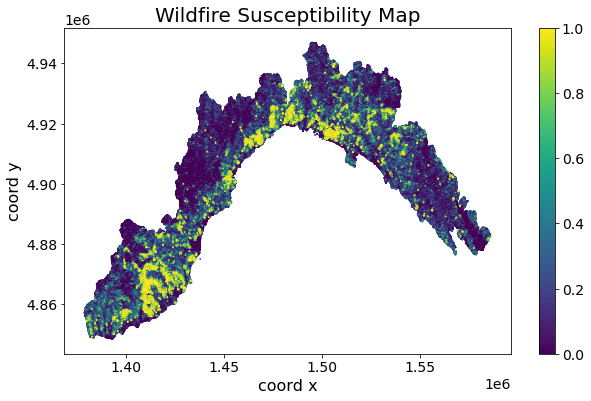

**How does it compare to the authors' map?** Compare the maps above with the authors' map qualitatively: the large-scale pattern (where the high-susceptibility areas are, e.g. along the coast versus the mountainous interior) should be similar if the model has captured the main drivers. Differences in smoothness and in the contrast of the probabilities are expected, since the authors use many more inputs and a more careful model-building and validation procedure than this short exercise. The fact that a model with only a few well-chosen inputs gets close to the full model's score and map is the useful result here: simpler models are easier to explain, cheaper to run, and less prone to learning spurious correlations.